# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1:


**Student(s):**
**Date:** 11/9/2026

In [1]:
# Your Phase 1 solution to the problem goes here.


### Q1. Clean the data, EDA and visualization

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

try:
    from google.colab import drive
    drive.mount('/content/drive')
    path = '/content/drive/MyDrive/DS3001/pierce_county_house_sales.csv'
except ImportError:
    path = 'pierce_county_house_sales.csv'

df = pd.read_csv(path)
print(df.shape)
df.head()

Mounted at /content/drive
(16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [3]:
print(df.dtypes)
print(df.isnull().sum())

sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object
sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
firep

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sale_price,16814.0,461233.191507,236083.342854,2000.0,348000.0,416500.0,523806.5,6130000.0
house_square_feet,16814.0,1879.941953,760.419008,1.0,1320.0,1774.0,2352.0,9510.0
attic_finished_square_feet,16814.0,24.945878,102.066417,0.0,0.0,0.0,0.0,1212.0
basement_square_feet,16814.0,167.852861,429.065832,0.0,0.0,0.0,0.0,4000.0
attached_garage_square_feet,16814.0,364.425122,286.454018,0.0,0.0,420.0,528.0,2816.0
detached_garage_square_feet,16814.0,38.298501,164.691471,0.0,0.0,0.0,0.0,3664.0
fireplaces,16814.0,0.889021,0.596731,0.0,1.0,1.0,1.0,5.0
stories,16814.0,1.558285,0.512055,0.0,1.0,2.0,2.0,3.0
year_built,16814.0,1980.469252,33.339025,1880.0,1959.0,1990.0,2006.0,2021.0
bedrooms,16814.0,3.277983,0.891240,0.0,3.0,3.0,4.0,25.0


In [5]:
cat_vars = ['hvac_description', 'exterior', 'interior', 'roof_cover',
            'waterfront_type', 'view_quality', 'utility_sewer']
for c in cat_vars:
    print(df[c].value_counts(dropna=False), '\n')

hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric                      2
Floor Wall Furnace            1
Name: count, dtype: int64 

exterior
Frame Siding              14577
Frame Vinyl                1724
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5
Unfinished Cottage            4
Pine Finished Cabin           4
Cedar A-Frame                 2
Pine Unfinished Cabin         2
Cedar Unfinished Cabin        2
NaN                           1
Pine A-Frame                  1
Name: count, dtype: int64 

interior
Drywall     16777
Paneling       30
NaN      

There are 16,814 sales, all from 2020, with 19 columns. Things that need cleaning:
- `sale_date` is a string, so it needs to be converted to a date.
- `waterfront_type` and `view_quality` are missing for almost every house. Here a missing value just means the house has no waterfront or no view, so I fill them in instead of dropping them.
- A few rows are missing `hvac_description`, `exterior`, `interior` or `roof_cover`.
- `interior` (99.8% Drywall) and `utility_sewer` (99.7% installed) are almost constant, so they can't explain price.
- Several categories are very rare (e.g. 1 "Pine A-Frame"), and "Floor Wall Furnace" is a typo of "Floor/Wall Furnace".
- Some values are impossible or suspicious: a $2,000 sale, a 1 sq ft house, a 25 bedroom house, and houses with 0 bathrooms or 0 stories.

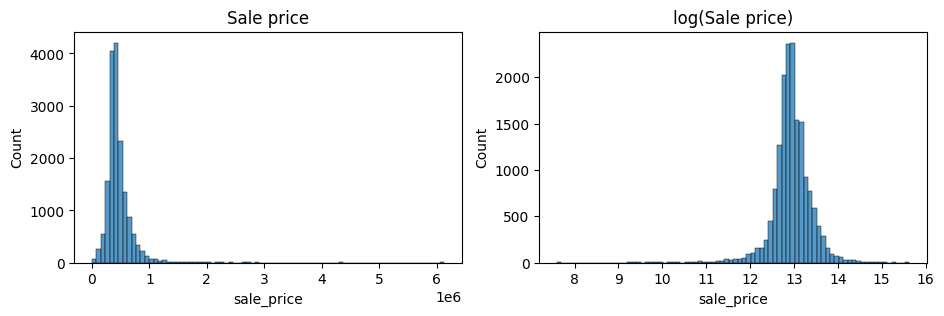

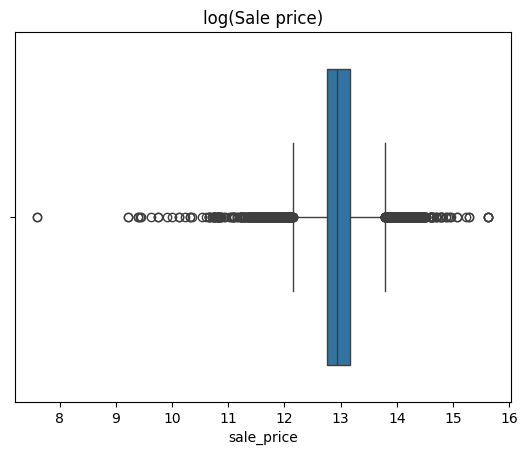

In [6]:
# Sale price has a very long right tail, so look at it in dollars and on a log scale
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.histplot(df['sale_price'], bins=80, ax=axes[0])
axes[0].set_title('Sale price')
sns.histplot(np.log(df['sale_price']), bins=80, ax=axes[1])
axes[1].set_title('log(Sale price)')
plt.show()

sns.boxplot(x=np.log(df['sale_price']))
plt.title('log(Sale price)')
plt.show()

In [7]:
# Cutoffs for the price outliers: 3 x IQR fences on log price
log_price = np.log(df['sale_price'])
q25, q75 = np.percentile(log_price, [25, 75])
iqr = q75 - q25
low, high = q25 - 3 * iqr, q75 + 3 * iqr
print('Price fences: $', round(np.exp(low)), 'to $', round(np.exp(high)))
print('Sales below low fence:', (log_price < low).sum())
print('Sales above high fence:', (log_price > high).sum())
print(df['sale_price'].sort_values().head(15).tolist())

Price fences: $ 102048 to $ 1786265
Sales below low fence: 139
Sales above high fence: 65
[2000, 2000, 10000, 10000, 12000, 12000, 12510, 12752, 15000, 17000, 17000, 20000, 22000, 25000, 25000]


In [8]:
# Look at the other suspicious values
print('House sq ft < 400:', (df['house_square_feet'] < 400).sum())
print(df['house_square_feet'].sort_values().head(10).tolist())
print(df['bedrooms'].value_counts().sort_index().to_dict())
print(df['bathrooms'].value_counts().sort_index().to_dict())
print(df['stories'].value_counts().sort_index().to_dict())

House sq ft < 400: 43
[1, 200, 216, 216, 238, 240, 252, 256, 272, 280]
{0: 47, 1: 337, 2: 1900, 3: 8504, 4: 4858, 5: 1028, 6: 113, 7: 19, 8: 4, 9: 3, 25: 1}
{0: 31, 1: 2940, 2: 6313, 3: 6816, 4: 633, 5: 73, 6: 7, 8: 1}
{0: 36, 1: 7450, 2: 9233, 3: 95}


Sale price is very right-skewed in dollars, but on a log scale it looks close to a bell curve with long tails on both ends. The very low sales (some under $20,000) are probably not normal market sales (family transfers, partial ownership, teardowns), and they would pull the regression a lot. I trim using **3 x IQR fences on log price**, which keeps sales between about \$102,000 and \$1.79 million and drops 139 low and 65 high sales. I used 3 x IQR instead of 1.5 x IQR because 1.5 x IQR would cut everything above about $975k, which removes a lot of real expensive houses.

I also drop houses under 400 sq ft, with 0 or more than 10 bedrooms, 0 bathrooms, or 0 stories, since those look like data entry errors. In total this removes about 300 of the 16,814 rows.

In [9]:
df = df.copy()
df['sale_date'] = pd.to_datetime(df['sale_date'])

# Missing waterfront / view means the house has no waterfront / no view
df['waterfront_type'] = df['waterfront_type'].fillna('None')
df['view_quality'] = df['view_quality'].fillna('No View')

# Only a handful of rows are missing hvac / exterior / roof, so drop them
df = df.dropna(subset=['hvac_description', 'exterior', 'roof_cover'])

# interior and utility_sewer are almost constant (>99.7% one value), so they can't explain price
df = df.drop(columns=['interior', 'utility_sewer'])

# Trim price outliers and impossible houses
log_price = np.log(df['sale_price'])
df = df[(log_price > low) & (log_price < high)]
df = df[df['house_square_feet'] >= 400]
df = df[df['bedrooms'].between(1, 10)]
df = df[(df['bathrooms'] > 0) & (df['stories'] > 0)]
print(df.shape)

(16510, 17)


In [10]:
# Fix typos and group rare categories together
df['hvac_description'] = df['hvac_description'].replace(
    {'Floor Wall Furnace': 'Floor/Wall Furnace', 'Electric': 'Electric Baseboard'})

def lump_rare(s, min_count=100):
    counts = s.value_counts()
    return s.where(s.isin(counts[counts >= min_count].index), 'Other')

for c in ['hvac_description', 'exterior', 'roof_cover']:
    df[c] = lump_rare(df[c])

df['waterfront'] = df['waterfront_type'].replace({
    'WF Lake': 'Lake', 'WF Salt': 'Salt',
    'WF Stream/Creek': 'Stream/River', 'WF River': 'Stream/River'})

view_map = {'No View': 'None',
            'View Lim -': 'Limited', 'View Lim': 'Limited', 'View Lim +': 'Limited',
            'View Avg': 'Average', 'View Avg +': 'Average',
            'View Good': 'Good', 'View Good +': 'Good', 'View V-Good': 'Good'}
df['view'] = df['view_quality'].map(view_map)

df['month'] = df['sale_date'].dt.month
df['age'] = 2020 - df['year_built']   # all sales are in 2020

for c in ['hvac_description', 'exterior', 'roof_cover', 'waterfront', 'view']:
    print(df[c].value_counts(), '\n')

hvac_description
Forced Air                10286
Electric Baseboard         2579
Heat Pump                  2033
Warm and Cool Air Zone     1242
Floor/Wall Furnace          169
Hot Water Baseboard         141
Other                        60
Name: count, dtype: int64 

exterior
Frame Siding            14348
Frame Vinyl              1709
Masonry Common Brick      203
Frame Stucco              152
Other                      98
Name: count, dtype: int64 

roof_cover
Composition Shingle    15529
Concrete Tile            293
Built Up Rock            232
Formed Seam Metal        207
Wood Shake               193
Other                     56
Name: count, dtype: int64 

waterfront
None            16038
Lake              197
Salt              164
Stream/River      111
Name: count, dtype: int64 

view
None       15615
Limited      570
Average      222
Good         103
Name: count, dtype: int64 



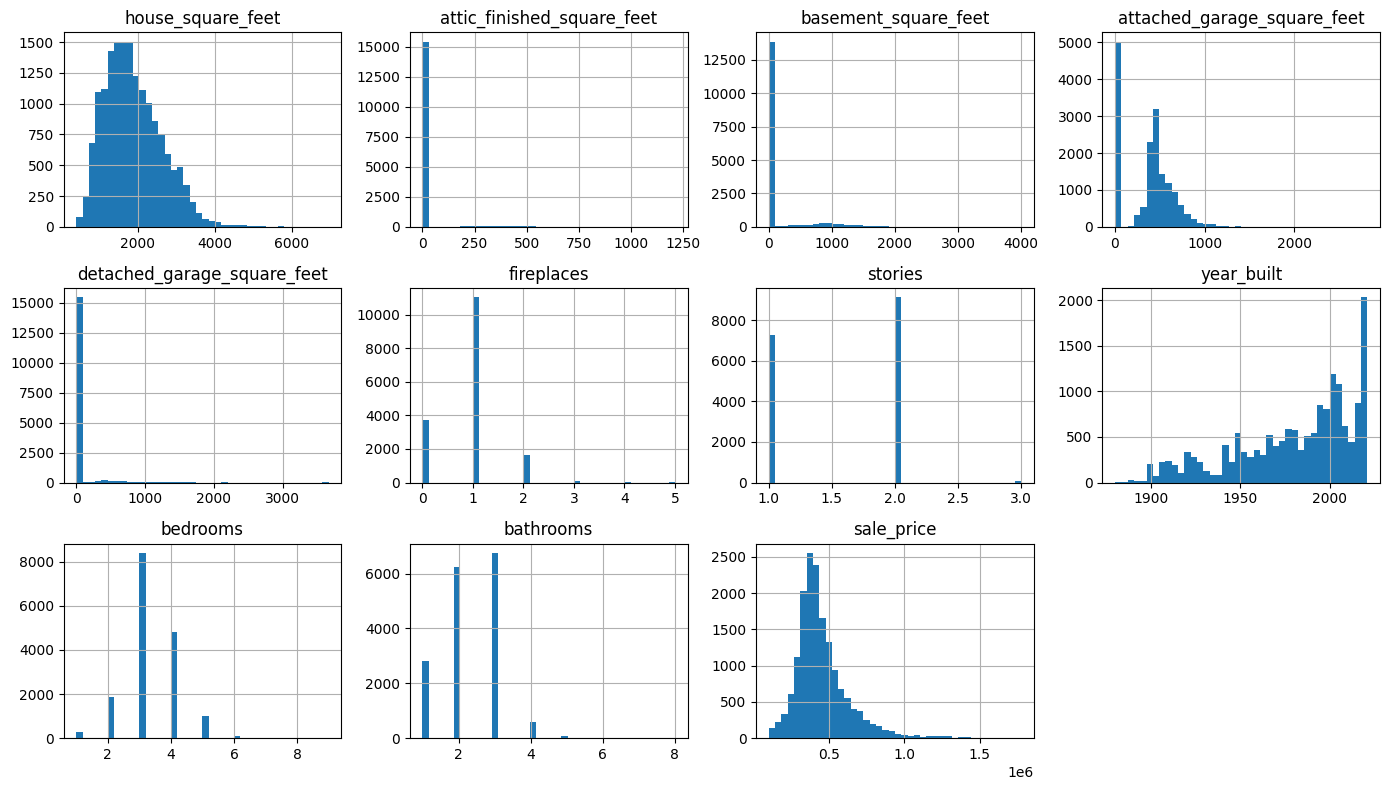

In [11]:
num_vars = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
            'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces',
            'stories', 'year_built', 'bedrooms', 'bathrooms']

df[num_vars + ['sale_price']].hist(figsize=(14, 8), bins=40, layout=(3, 4))
plt.tight_layout()
plt.show()

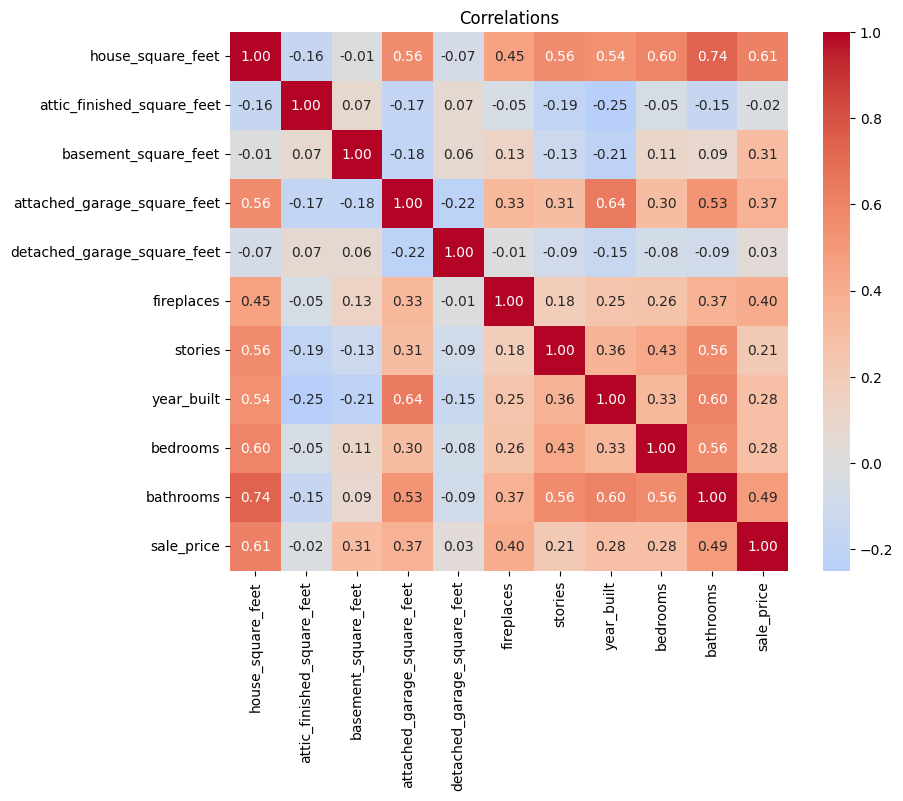

sale_price                     1.000000
house_square_feet              0.612396
bathrooms                      0.488651
fireplaces                     0.399649
attached_garage_square_feet    0.372258
basement_square_feet           0.310511
year_built                     0.284394
bedrooms                       0.282460
stories                        0.214367
detached_garage_square_feet    0.034905
attic_finished_square_feet    -0.021051
Name: sale_price, dtype: float64


In [12]:
corr = df[num_vars + ['sale_price']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlations')
plt.show()
print(corr['sale_price'].sort_values(ascending=False))

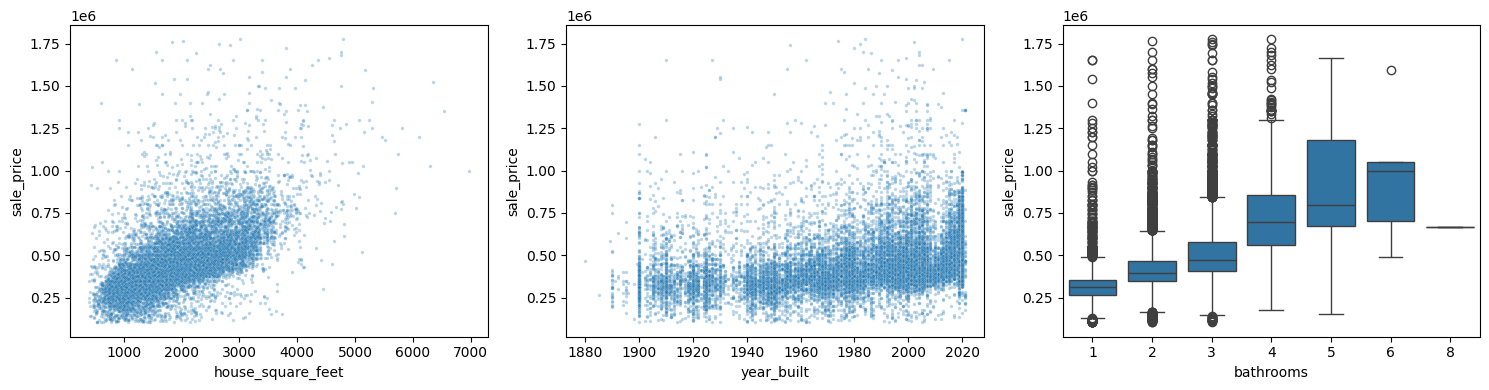

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x='house_square_feet', y='sale_price', s=6, alpha=0.3, ax=axes[0])
sns.scatterplot(data=df, x='year_built', y='sale_price', s=6, alpha=0.3, ax=axes[1])
sns.boxplot(data=df, x='bathrooms', y='sale_price', ax=axes[2])
plt.tight_layout()
plt.show()

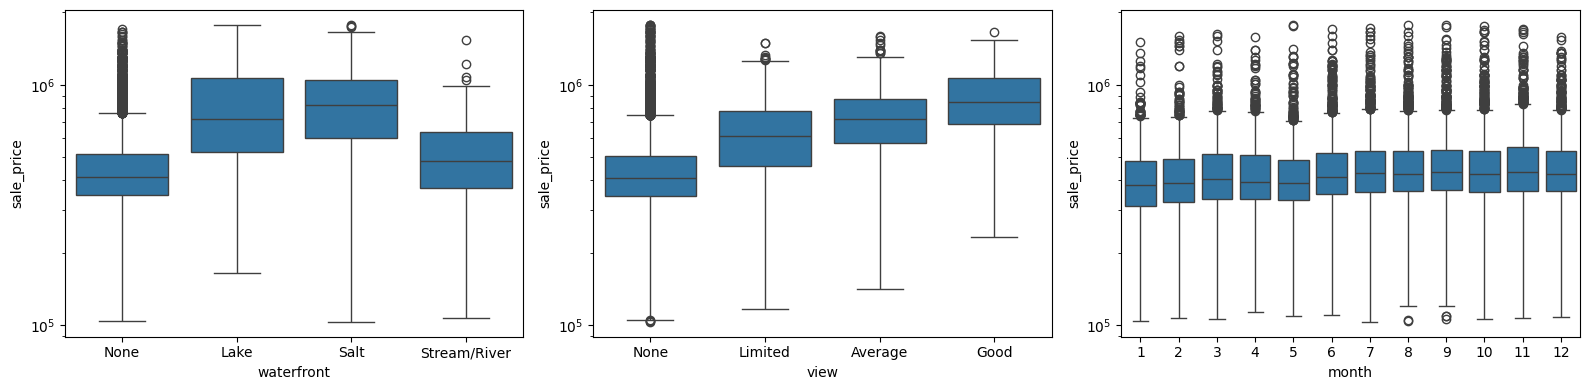

waterfront
Lake            721000.0
None            415000.0
Salt            826000.0
Stream/River    480000.0
Name: sale_price, dtype: float64
view
Average    720100.0
Good       849950.0
Limited    610000.0
None       410000.0
Name: sale_price, dtype: float64
month
1     383000.0
2     390000.0
3     405000.0
4     395000.0
5     390000.0
6     415000.0
7     429999.0
8     425000.0
9     432750.0
10    425500.0
11    435000.0
12    425250.0
Name: sale_price, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='waterfront', y='sale_price', ax=axes[0])
sns.boxplot(data=df, x='view', y='sale_price', order=['None', 'Limited', 'Average', 'Good'], ax=axes[1])
sns.boxplot(data=df, x='month', y='sale_price', ax=axes[2])
for ax in axes:
    ax.set_yscale('log')
plt.tight_layout()
plt.show()

print(df.groupby('waterfront')['sale_price'].median())
print(df.groupby('view')['sale_price'].median())
print(df.groupby('month')['sale_price'].median())

After cleaning there are 16,510 sales.

- **Size matters most.** House square feet has the highest correlation with price (0.61), followed by bathrooms (0.49), fireplaces (0.40) and attached garage (0.37). Bedrooms is only 0.28 because it mostly moves with square feet.
- **The spread grows with size.** In the square feet scatterplot, the spread of prices fans out for bigger houses. That suggests modeling log price.
- **Age is not a straight line.** Houses built before about 1940 sell for about the same as mid-century houses, and prices rise mostly for houses built after about 1980.
- **Many zeros.** Attic, basement and detached garage are 0 for most houses, so the main question for those is whether the house has one at all.
- **Waterfront and view carry large premiums.** Median price is \$826k for saltwater and \$721k for lake houses vs \$415k for no waterfront, and \$850k for a good view vs \$410k for no view. These are rare, but they matter a lot.
- **Prices rose during 2020.** The median price went from \$383k in January to about \$430k from July on, so sale month should be in the model.

### Q2. Transform the variables for regression

In [15]:
# One-hot encode the categorical variables. drop_first=True avoids the dummy variable trap,
# since the model has an intercept.
cat_vars = ['hvac_description', 'exterior', 'roof_cover', 'waterfront', 'view', 'month']
dummies = pd.get_dummies(df[cat_vars].astype(str), drop_first=True, dtype=int)

X = pd.concat([df[num_vars], dummies], axis=1)
y = df['sale_price']
print(X.shape)
print(list(dummies.columns))

(16510, 42)
['hvac_description_Floor/Wall Furnace', 'hvac_description_Forced Air', 'hvac_description_Heat Pump', 'hvac_description_Hot Water Baseboard', 'hvac_description_Other', 'hvac_description_Warm and Cool Air Zone', 'exterior_Frame Stucco', 'exterior_Frame Vinyl', 'exterior_Masonry Common Brick', 'exterior_Other', 'roof_cover_Composition Shingle', 'roof_cover_Concrete Tile', 'roof_cover_Formed Seam Metal', 'roof_cover_Other', 'roof_cover_Wood Shake', 'waterfront_None', 'waterfront_Salt', 'waterfront_Stream/River', 'view_Good', 'view_Limited', 'view_None', 'month_10', 'month_11', 'month_12', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9']


- The categorical variables (heating, exterior, roof, waterfront, view, and sale month) are one-hot encoded with `pd.get_dummies(drop_first=True)` so the intercept doesn't cause the dummy variable trap. The dropped base categories are Electric Baseboard, Frame Siding, Built Up Rock, Lake waterfront, Average view and January, so each dummy coefficient is measured relative to those.
- Rare categories are grouped into "Other", and the waterfront and view levels are combined into four groups each, so no dummy is based on just a few houses.
- `sale_date` is turned into `month`, and `year_built` is turned into `age` (2020 minus year built).
- For Q4 the numeric variables are left as they are. Log, IHS, squared and interaction terms are added in Q6.

### Q3. 80/20 train-test split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

13208 3302


### Q4. Simple linear models

In [17]:
def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))

def r2(y, y_hat):
    return 1 - np.sum((y - y_hat) ** 2) / np.sum((y - np.mean(y)) ** 2)

results = []

def show_results():
    out = pd.DataFrame(results)
    for c in ['train_RMSE', 'test_RMSE']:
        out[c] = out[c].map(lambda v: f'{v:,.0f}')
    for c in ['train_R2', 'test_R2']:
        out[c] = out[c].map(lambda v: f'{v:.3f}' if abs(v) < 1e3 else f'{v:.2e}')
    return out

def fit_simple(name, cols):
    reg = LinearRegression().fit(X_train[cols], y_train)
    pred_train = reg.predict(X_train[cols])
    pred_test = reg.predict(X_test[cols])
    results.append({'model': name, 'n_features': len(cols),
                    'train_RMSE': rmse(y_train, pred_train), 'test_RMSE': rmse(y_test, pred_test),
                    'train_R2': r2(y_train, pred_train), 'test_R2': r2(y_test, pred_test)})
    return reg

size_vars = ['house_square_feet']
basic_vars = ['house_square_feet', 'bedrooms', 'bathrooms', 'year_built']
all_vars = list(X.columns)

reg1 = fit_simple('1: square feet', size_vars)
reg2 = fit_simple('2: sq ft, beds, baths, year', basic_vars)
reg3 = fit_simple('3: all numeric', num_vars)
reg4 = fit_simple('4: all numeric + categorical', all_vars)

show_results()

,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641


In [18]:
pd.Series(reg4.coef_, index=all_vars).round(1).sort_values()

,0
waterfront_None,-272724.5
waterfront_Stream/River,-247117.0
view_None,-150319.3
view_Limited,-68350.1
hvac_description_Other,-53379.0
exterior_Frame Vinyl,-35965.2
stories,-29985.6
bedrooms,-22070.3
hvac_description_Forced Air,-2372.2
exterior_Masonry Common Brick,-2104.1


**Model 4 (all numeric variables plus the categorical dummies) does best**, with a test RMSE of about \$107,400 and a test $R^2$ of 0.641. Each model improves on the one before it. Square feet alone explains 39% of the variation, and adding the categorical variables (mostly waterfront, view and month) raises that from 0.53 to 0.64.

Train and test scores are very close for all four models, so none of them is overfitting. Test is even a little better than train, which is just from the random split. They are more likely **underfitting**, since a typical miss is still more than \$100k.

Some coefficients from model 4, each holding the others fixed:
- Each extra square foot adds about \$140.
- An extra bedroom *lowers* the price by about \$22k, because at the same square feet more bedrooms means smaller rooms.
- Having no waterfront is \$273k below a lake house, and a good view is \$79k above an average view.
- December sales are about \$63k above January sales.

The biggest missing piece is **location** (neighborhood, school district, lot size), which isn't in the data. That limits how high $R^2$ can get.

### Q5. Partial correlation (partial regression) plots

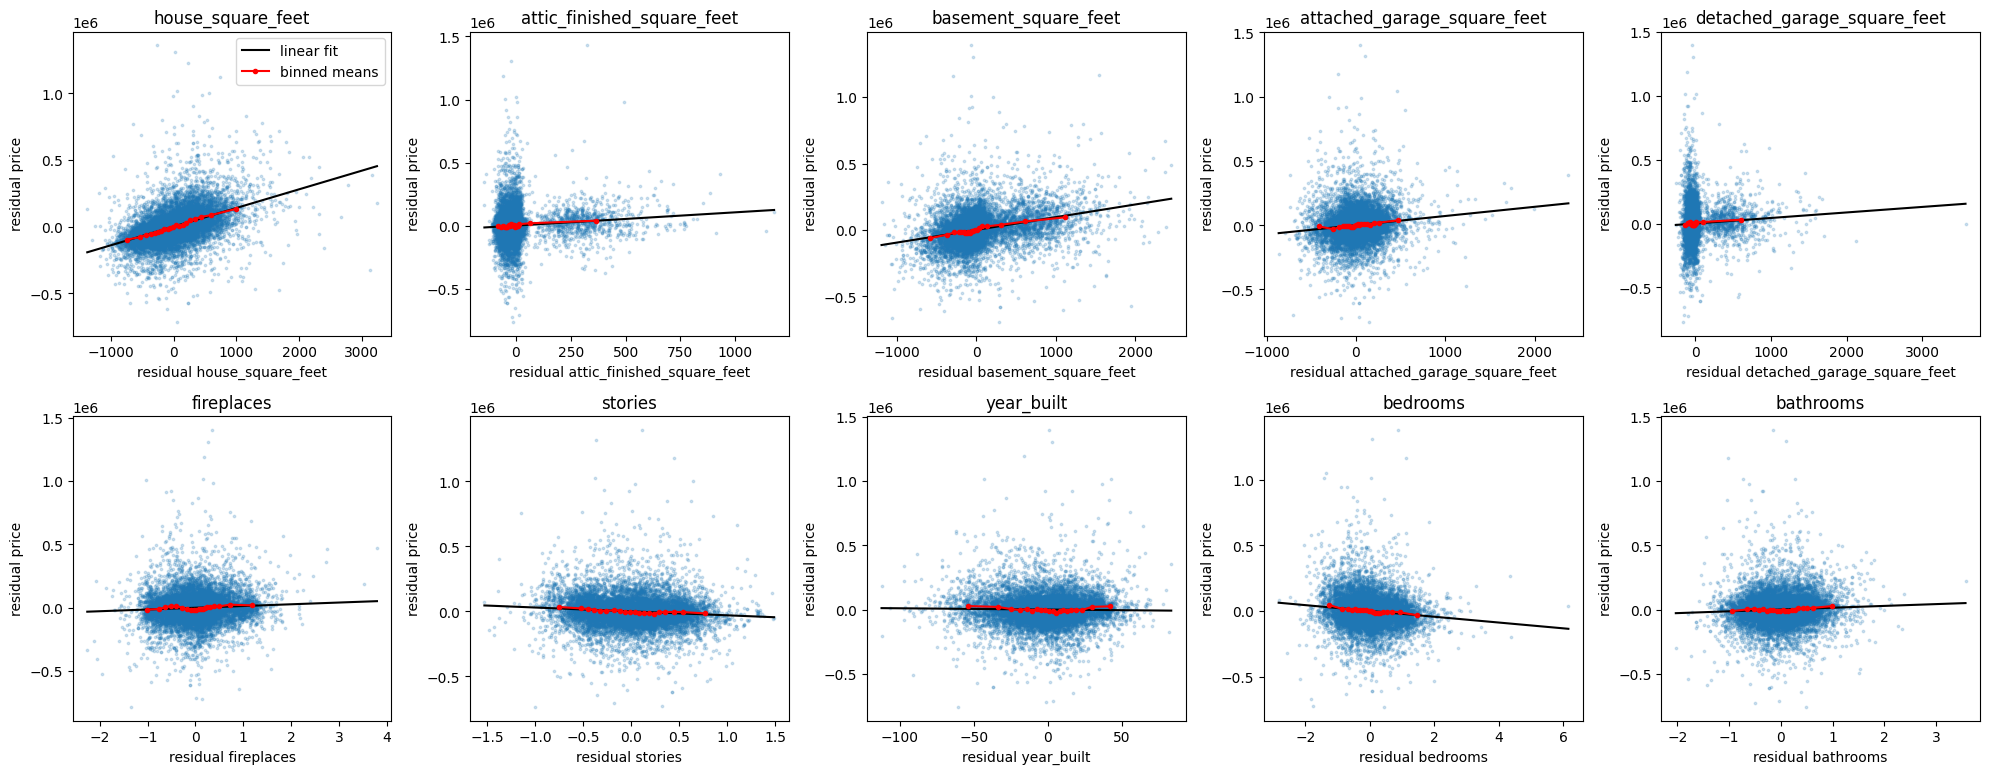

In [19]:
# For each numeric variable x: regress price on every OTHER feature in model 4,
# regress x on every other feature, then plot the two sets of residuals.
# The slope of that plot is x's coefficient in model 4 (partialling out, from class).
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for var, ax in zip(num_vars, axes.flatten()):
    others = [c for c in all_vars if c != var]
    r_price = y_train - LinearRegression().fit(X_train[others], y_train).predict(X_train[others])
    r_x = X_train[var] - LinearRegression().fit(X_train[others], X_train[var]).predict(X_train[others])

    ax.scatter(r_x, r_price, s=3, alpha=0.2)
    slope = np.inner(r_x - r_x.mean(), r_price - r_price.mean()) / np.inner(r_x - r_x.mean(), r_x - r_x.mean())
    grid = np.linspace(r_x.min(), r_x.max(), 50)
    ax.plot(grid, slope * grid, color='black', label='linear fit')

    # binned means show any curvature the straight line misses
    bins = pd.qcut(r_x, 20, duplicates='drop')
    binned = pd.DataFrame({'x': r_x, 'y': r_price}).groupby(bins, observed=True).mean()
    ax.plot(binned['x'], binned['y'], color='red', marker='o', ms=3, label='binned means')

    ax.set_title(var)
    ax.set_xlabel('residual ' + var)
    ax.set_ylabel('residual price')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

Each plot shows the residuals of price against the residuals of one variable after partialling out every other feature in model 4, the same method as the class slides. The black line's slope is that variable's coefficient, and the red dots are binned means.

**No strong non-linearities.** The binned means mostly follow the straight line, so after controlling for the other features each variable enters close to linearly in dollars. The smaller patterns I see:
- **year_built** is a little U-shaped: the oldest and newest houses are slightly above the line in the middle. That supports adding age².
- **house_square_feet**: the points spread out more for bigger houses (also seen in the EDA). Effects that grow with size are better modeled as percentages, so I use log price and log square feet in Q6.
- **attic, basement, detached garage**: most points are piled at zero with a few spread out to the right. Having one vs not seems to matter more than the exact size, so I use the inverse hyperbolic sine, which compresses large values and still works at 0.
- **bedrooms** has a clearly negative slope once size is controlled for, which matches the coefficient in Q4.

### Q6. A more complex model with transformations and interactions

In [20]:
def build_features(D):
    F = pd.DataFrame(index=D.index)
    F['log_sqft'] = np.log(D['house_square_feet'])
    F['age'] = 2020 - D['year_built']
    F['age_sq'] = F['age'] ** 2
    # inverse hyperbolic sine handles the zeros (no basement, no garage, ...)
    for c in ['attic_finished_square_feet', 'basement_square_feet',
              'attached_garage_square_feet', 'detached_garage_square_feet']:
        F['ihs_' + c] = np.arcsinh(D[c])
    for c in ['fireplaces', 'stories', 'bedrooms', 'bathrooms']:
        F[c] = D[c]
    dummy_cols = [c for c in D.columns if c not in num_vars]
    F = pd.concat([F, D[dummy_cols]], axis=1)

    # interactions
    F['log_sqft_x_age'] = F['log_sqft'] * F['age']
    for c in dummy_cols:
        if c.startswith('waterfront') or c.startswith('view'):
            F['log_sqft_x_' + c] = F['log_sqft'] * F[c]
    F['beds_x_baths'] = F['bedrooms'] * F['bathrooms']
    F.columns = F.columns.str.replace(' ', '_')   # no spaces, so interaction names split cleanly
    return F

F_train = build_features(X_train)
F_test = build_features(X_test)
print(F_train.shape)

(13208, 51)


In [21]:
# Fit on log price, then convert predictions back to dollars so the RMSE is comparable
# with the simple models. exp(prediction) estimates the median, so multiply by the mean of
# exp(residuals) (Duan's smearing estimate) to get back to the mean.
def fit_log_model(name, model, Xtr, Xte):
    model.fit(Xtr, np.log(y_train))
    smear = np.mean(np.exp(np.log(y_train) - model.predict(Xtr)))
    pred_train = np.exp(model.predict(Xtr)) * smear
    pred_test = np.exp(model.predict(Xte)) * smear
    results.append({'model': name, 'n_features': Xtr.shape[1],
                    'train_RMSE': rmse(y_train, pred_train), 'test_RMSE': rmse(y_test, pred_test),
                    'train_R2': r2(y_train, pred_train), 'test_R2': r2(y_test, pred_test)})
    print(name, '| log-scale R2 train:', round(r2(np.log(y_train), model.predict(Xtr)), 3),
          'test:', round(r2(np.log(y_test), model.predict(Xte)), 3))
    return model

reg5 = fit_log_model('5: log price, transforms + interactions', LinearRegression(), F_train, F_test)
show_results()

5: log price, transforms + interactions | log-scale R2 train: 0.577 test: 0.586


,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641
4,"5: log price, transforms + interactions",51,"111,638","106,223",0.631,0.649


In [22]:
coefs5 = pd.Series(reg5.coef_, index=F_train.columns)
coefs5[[c for c in F_train.columns if not c.startswith(('hvac', 'exterior', 'roof', 'month'))]].round(4)

,0
log_sqft,0.4100
age,0.0065
age_sq,0.0000
ihs_attic_finished_square_feet,0.0120
ihs_basement_square_feet,0.0248
ihs_attached_garage_square_feet,0.0052
ihs_detached_garage_square_feet,0.0063
fireplaces,0.0391
stories,-0.0802
bedrooms,-0.0318


In [23]:
# What happens if we keep adding complexity? Expand every feature into all squares and
# pairwise interactions (degree-2 polynomial).
poly = PolynomialFeatures(degree=2, include_bias=False)
P_train = pd.DataFrame(poly.fit_transform(F_train), columns=poly.get_feature_names_out(F_train.columns))
P_test = pd.DataFrame(poly.transform(F_test), columns=P_train.columns)

# A dummy squared is the same dummy, and two dummies from the same category multiply to all zeros.
# Drop those duplicate / constant columns, then standardize so the features are on the same scale.
keep = (~P_train.T.duplicated()) & (P_train.std() > 0)
P_train, P_test = P_train.loc[:, keep], P_test.loc[:, keep]
scaler = StandardScaler().fit(P_train)
P_train = pd.DataFrame(scaler.transform(P_train), columns=P_train.columns)
P_test = pd.DataFrame(scaler.transform(P_test), columns=P_train.columns)
print(P_train.shape)

reg6 = fit_log_model('6: degree-2 expansion of model 5', LinearRegression(), P_train, P_test)
show_results()

(13208, 1165)
6: degree-2 expansion of model 5 | log-scale R2 train: 0.67 test: -8.667


,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641
4,"5: log price, transforms + interactions",51,"111,638","106,223",0.631,0.649
5,6: degree-2 expansion of model 5,1165,"93,089","177,703,646,413,194,144",0.744,-9.83e+23


**Model 5** uses log price as the outcome and adds:
- log square feet, so effects are in percentages
- age and age², for the U-shape
- IHS transforms for the zero-heavy attic, basement and garage areas
- interactions: size x age (does an extra square foot matter less in an old house?), size x waterfront and size x view (does a view add more to a bigger house?), and bedrooms x bathrooms

Predictions are converted back to dollars so the RMSE is comparable with Q4. Exponentiating a log prediction gives roughly the median, not the mean, so I multiply by the average of exp(residuals) (Duan's smearing estimate).

**Results.** Model 5 has a test RMSE of about \$106,200 and a test $R^2$ of 0.649 (0.586 on the log scale). That is better than model 4, but only slightly (about \$1,200 lower RMSE). The extra structure is real, but most of what's left unexplained is location, which no transformation of these features can fix. The coefficient on log square feet is about 0.46, so a 10% bigger house sells for about 4.6% more at the base category.

**Model 6** takes model 5 and adds every square and pairwise interaction, giving 1,165 features. Its training fit is the best of any model (\$93k RMSE, $R^2$ 0.744), but on the test set it falls apart: test $R^2$ is hugely negative. Its median test error is a normal ~11%, but a few test houses with unusual combinations of features get absurd predictions (two above \$500 million), and squared error lets those few misses dominate. That is **overfitting**: the model memorized the training data with features that don't generalize.

### Q7. Summary

In [24]:
summary = pd.DataFrame(results)
show_results()

,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641
4,"5: log price, transforms + interactions",51,"111,638","106,223",0.631,0.649
5,6: degree-2 expansion of model 5,1165,"93,089","177,703,646,413,194,144",0.744,-9.83e+23


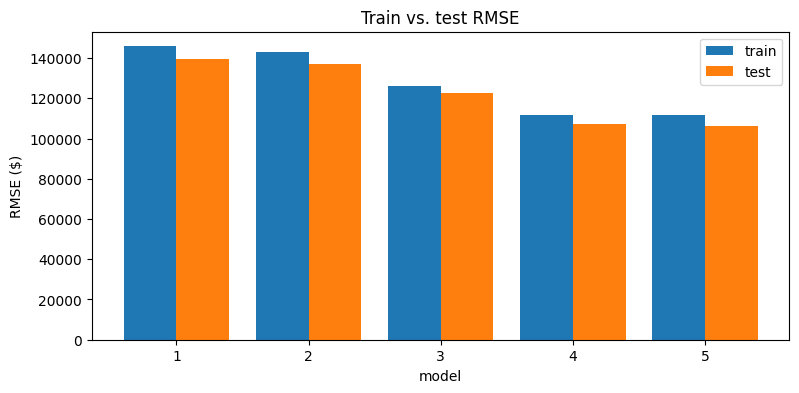

In [25]:
plot_df = summary[summary['test_R2'] > 0]   # model 6 is off the chart
x = np.arange(len(plot_df))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, plot_df['train_RMSE'], width=0.4, label='train')
plt.bar(x + 0.2, plot_df['test_RMSE'], width=0.4, label='test')
plt.xticks(x, plot_df['model'].str.split(':').str[0])
plt.xlabel('model')
plt.ylabel('RMSE ($)')
plt.title('Train vs. test RMSE')
plt.legend()
plt.show()

**Summary of 1 to 6:**
1. Cleaning mattered: dropping non-market sales and impossible houses, filling missing waterfront and view as "None", and grouping rare categories.
2. Size, bathrooms, waterfront, view and sale month were the clearest drivers of price in the EDA.
3. The simple linear models improved steadily as features were added. The best simple model (4) reached a test $R^2$ of 0.64 with almost no gap between train and test.
4. The partial regression plots showed the variables are close to linear, with mild curvature in age and more spread for bigger houses.
5. The transformed and interacted model (5) was the best, but only slightly better than model 4.
6. Expanding into every square and interaction (model 6) gave the best training score and the worst test score by far.

**Overfitting, underfitting and model selection:**
- Models 1 to 3 **underfit**. They were too simple, and their train and test errors were both high and close together.
- Model 6 **overfit**. Training error kept going down while test error exploded, the same pattern as k = 1 in k-NN.
- The best model sits in between. More features only help when they represent real structure, and training error can't tell the two cases apart, because it always improves as you add features. That's why the model has to be chosen on held-out data.
- A good model does not always need to be complicated. The careful model 5 barely beat the plain model 4, because the biggest missing driver (location) isn't in the data. Better data would matter more here than a fancier model.

### Q8. Lasso

Best alpha: 0.0026366508987303583


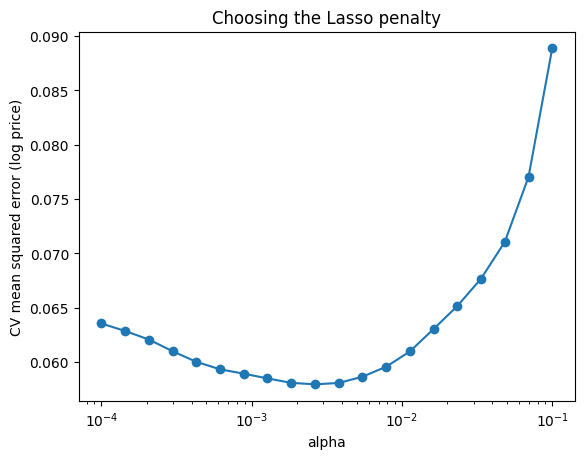

In [26]:
# Run the Lasso on the big degree-2 expansion (already standardized) from model 6.
# Choose the penalty alpha by 5-fold cross-validation on the training set only.
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)  # very small alphas converge slowly

alphas = np.logspace(-4, -1, 20)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=5000, n_jobs=-1).fit(P_train, np.log(y_train))
best_alpha = lasso_cv.alpha_
print('Best alpha:', best_alpha)

plt.plot(lasso_cv.alphas_, lasso_cv.mse_path_.mean(axis=1), marker='o')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('CV mean squared error (log price)')
plt.title('Choosing the Lasso penalty')
plt.show()

In [27]:
lasso = fit_log_model('7: Lasso on degree-2 expansion', Lasso(alpha=best_alpha, max_iter=10000), P_train, P_test)

lasso_coefs = pd.Series(lasso.coef_, index=P_train.columns)
selected = lasso_coefs[lasso_coefs != 0]
print('Features kept:', len(selected), 'of', len(lasso_coefs))
show_results()

7: Lasso on degree-2 expansion | log-scale R2 train: 0.598 test: 0.585
Features kept: 196 of 1165


,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641
4,"5: log price, transforms + interactions",51,"111,638","106,223",0.631,0.649
5,6: degree-2 expansion of model 5,1165,"93,089","177,703,646,413,194,144",0.744,-9.83e+23
6,7: Lasso on degree-2 expansion,1165,"108,560","106,789",0.652,0.645


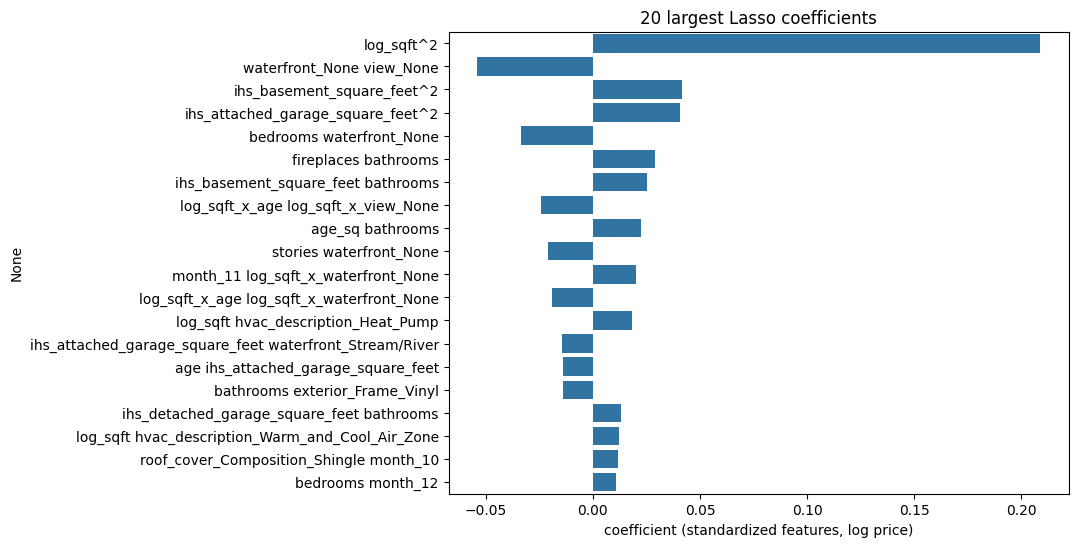

,0
log_sqft^2,0.2088
waterfront_None view_None,-0.0542
ihs_basement_square_feet^2,0.0414
ihs_attached_garage_square_feet^2,0.0406
bedrooms waterfront_None,-0.0337
fireplaces bathrooms,0.0290
ihs_basement_square_feet bathrooms,0.0251
log_sqft_x_age log_sqft_x_view_None,-0.0244
age_sq bathrooms,0.0227
stories waterfront_None,-0.0211


In [28]:
top = selected.reindex(selected.abs().sort_values(ascending=False).index).head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index)
plt.xlabel('coefficient (standardized features, log price)')
plt.title('20 largest Lasso coefficients')
plt.show()
top.round(4)

In [29]:
# Which original variables does the Lasso use? Count the kept terms (alone, squared, or in an
# interaction) that involve each variable, grouping the dummies back into their original variable.
def original_var(col):
    for prefix in ['hvac_description', 'exterior', 'roof_cover', 'waterfront', 'view', 'month']:
        if col.startswith(prefix):
            return prefix
    return col

rows = []
for col in F_train.columns:
    terms = [n for n in selected.index if col in n.replace('^2', '').split(' ')]
    rows.append({'variable': original_var(col), 'kept_terms': len(terms), 'kept_alone': col in selected.index})
usage = pd.DataFrame(rows).groupby('variable').agg(kept_terms=('kept_terms', 'sum'),
                                                   kept_alone=('kept_alone', 'any'))
usage.sort_values('kept_terms', ascending=False)

,kept_terms,kept_alone
variable,,
month,80,True
hvac_description,53,False
roof_cover,37,False
exterior,34,False
waterfront,28,True
view,15,False
ihs_basement_square_feet,13,False
ihs_detached_garage_square_feet,13,False
bathrooms,11,False


The degree-2 Lasso is hard to read, because it often keeps a square or interaction instead of the plain feature. So I also ran the Lasso on just the 51 features of model 5.

In [30]:
# Easier to interpret: Lasso on the 51 features of model 5 (standardized)
scaler5 = StandardScaler().fit(F_train)
S_train = pd.DataFrame(scaler5.transform(F_train), columns=F_train.columns)
S_test = pd.DataFrame(scaler5.transform(F_test), columns=F_train.columns)

lasso_cv5 = LassoCV(alphas=alphas, cv=5, max_iter=5000).fit(S_train, np.log(y_train))
print('Best alpha:', lasso_cv5.alpha_)
lasso5 = fit_log_model('8: Lasso on model 5 features', Lasso(alpha=lasso_cv5.alpha_, max_iter=10000), S_train, S_test)

coefs_l5 = pd.Series(lasso5.coef_, index=F_train.columns)
print('Features kept:', (coefs_l5 != 0).sum(), 'of', len(coefs_l5))
print('Dropped:', list(coefs_l5.index[coefs_l5 == 0]))
show_results()

Best alpha: 0.0001
8: Lasso on model 5 features | log-scale R2 train: 0.576 test: 0.586
Features kept: 47 of 51
Dropped: ['waterfront_Salt', 'waterfront_Stream/River', 'log_sqft_x_view_Good', 'log_sqft_x_view_Limited']


,model,n_features,train_RMSE,test_RMSE,train_R2,test_R2
0,1: square feet,1,"145,837","139,806",0.371,0.391
1,"2: sq ft, beds, baths, year",4,"142,832","137,175",0.397,0.414
2,3: all numeric,10,"126,260","122,613",0.529,0.532
3,4: all numeric + categorical,42,"111,947","107,431",0.629,0.641
4,"5: log price, transforms + interactions",51,"111,638","106,223",0.631,0.649
5,6: degree-2 expansion of model 5,1165,"93,089","177,703,646,413,194,144",0.744,-9.83e+23
6,7: Lasso on degree-2 expansion,1165,"108,560","106,789",0.652,0.645
7,8: Lasso on model 5 features,51,"111,656","106,309",0.631,0.648


In [31]:
kept5 = coefs_l5[coefs_l5 != 0]
kept5.reindex(kept5.abs().sort_values(ascending=False).index).round(4)

,0
log_sqft,0.2088
view_None,-0.1797
log_sqft_x_age,-0.1657
log_sqft_x_view_None,0.1209
age,0.0905
ihs_basement_square_feet,0.0693
age_sq,0.0628
log_sqft_x_waterfront_None,-0.0510
month_11,0.0412
stories,-0.0406


**Lasso on the degree-2 expansion (model 7).** Cross-validation picks $\alpha \approx 0.0026$. The Lasso keeps **196 of the 1,165 features** and sets the rest exactly to zero. Its test RMSE is about \$106,800 and test $R^2$ is 0.645 (0.585 on the log scale). It turns the badly overfit model 6 (test $R^2$ far below zero) into a model about as good as model 5, and its train and test scores are close again.

Its largest coefficients are:
- log square feet² (size)
- no waterfront x no view (a penalty for having neither)
- basement and attached garage area
- bedrooms x no waterfront
- fireplaces x bathrooms
- several size x age terms

Every original variable shows up in at least a few kept terms. Month, heating type and waterfront are used the most.

These selections are harder to read than they look. When features are highly correlated (log_sqft and log_sqft², or a dummy and its interactions), the Lasso tends to keep one and drop the others fairly arbitrarily. So a feature being dropped doesn't mean it doesn't matter.

**Lasso on the 51 model 5 features (model 8).** Cross-validation chose the smallest $\alpha$ in the grid (0.0001), so model 5 needs almost no regularization; it wasn't overfitting to begin with. The Lasso keeps **47 of 51** features. It drops waterfront_Salt, waterfront_Stream/River, log_sqft x view_Good and log_sqft x view_Limited, which are redundant once the other waterfront and view terms are included. The most predictive features are:
- log square feet
- no view
- size x age
- age and age²
- basement area
- size x no waterfront
- the late-2020 months

Test RMSE is about \$106,300 and test $R^2$ is 0.648, basically the same as model 5.

**Takeaway.** The Lasso is most useful when there are too many features. It automatically shrinks a 1,165-feature model back to something that generalizes. When the model is already reasonable, it changes little.

## *Phase 2:
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [32]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]